In [25]:
#Problem Statement: The Soil Conservation Office needs to identify geographic areas where soil conservation efforts should be prioritized because it must direct limited resources toward locations where conservation interventions can most effectively reduce drought-related crop losses.

In [26]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import plotly.express as px
from src.data_loader import load_master

df = load_master()
print(f"{len(df):,} rows × {len(df.columns)} columns")
df.head(15)

17,056 rows × 21 columns


,fips,county_name,state_alpha,year,crop,yield_per_acre,yield_status,acres_planted,acres_harvested,yield_anomaly_pct,...,precip_anomaly_pct,tavg_c,extreme_heat_days,gdd,max_drought_severity,weeks_in_d2_plus,mean_dsci,aws_100cm_mm,droughty_pct,nccpi_crop
0,06001,Alameda County,CA,2000,CORN,116.7,reported,600.0,600.0,NaN,...,76.00,20.06,5.0,1507.0,0.0,0.0,0.0,116.899535,62.153917,0.0675
1,06001,Alameda County,CA,2001,CORN,155.0,reported,400.0,400.0,NaN,...,-65.89,20.70,5.0,1591.0,2.0,0.0,69.4,116.899535,62.153917,0.0675
2,06001,Alameda County,CA,2002,CORN,NaN,not_reported,NaN,NaN,NaN,...,-5.11,19.93,6.0,1484.0,1.0,0.0,85.7,116.899535,62.153917,0.0675
3,06001,Alameda County,CA,2003,CORN,152.5,reported,500.0,400.0,NaN,...,12.34,20.58,8.0,1572.0,0.0,0.0,0.0,116.899535,62.153917,0.0675
4,06001,Alameda County,CA,2004,CORN,NaN,not_reported,NaN,NaN,NaN,...,-32.16,20.23,3.0,1537.0,1.0,0.0,59.1,116.899535,62.153917,0.0675
5,06001,Alameda County,CA,2005,CORN,NaN,not_reported,NaN,NaN,NaN,...,154.16,19.78,1.0,1470.0,0.0,0.0,0.0,116.899535,62.153917,0.0675
6,06001,Alameda County,CA,2006,CORN,NaN,not_reported,NaN,NaN,NaN,...,-5.15,20.48,8.0,1550.0,0.0,0.0,0.0,116.899535,62.153917,0.0675
7,06001,Alameda County,CA,2007,CORN,NaN,not_reported,NaN,NaN,NaN,...,-51.53,19.75,2.0,1473.0,3.0,19.0,253.7,116.899535,62.153917,0.0675
8,06001,Alameda County,CA,2008,CORN,NaN,not_reported,NaN,NaN,NaN,...,-99.14,20.06,11.0,1491.0,3.0,10.0,227.2,116.899535,62.153917,0.0675
9,06001,Alameda County,CA,2009,CORN,NaN,not_reported,NaN,NaN,NaN,...,31.82,20.30,6.0,1525.0,3.0,22.0,237.7,116.899535,62.153917,0.0675


In [27]:
df.describe()

,year,yield_per_acre,acres_planted,acres_harvested,yield_anomaly_pct,precip_mm,precip_anomaly_pct,tavg_c,extreme_heat_days,gdd,max_drought_severity,weeks_in_d2_plus,mean_dsci,aws_100cm_mm,droughty_pct,nccpi_crop
count,17056.00000,11639.000000,11715.000000,11639.000000,10995.000000,17056.000000,17056.000000,17056.000000,17056.000000,17056.000000,16906.000000,16906.000000,16906.000000,17056.000000,17056.000000,17056.000000
mean,2012.50000,102.143792,83763.972685,81243.172953,-0.010008,476.040455,-0.000022,17.293810,8.911585,1980.892706,2.152076,5.844907,100.540293,158.574977,33.918333,0.491369
std,7.50022,61.013716,61482.305720,60481.989542,13.161985,224.332444,35.186833,5.089643,14.857065,690.923373,1.436294,10.011786,115.067538,37.765280,31.500504,0.223265
min,2000.00000,8.700000,100.000000,50.000000,-77.840000,0.000000,-100.000000,2.890000,0.000000,794.000000,0.000000,0.000000,0.000000,66.882411,0.000000,0.001000
25%,2006.00000,50.300000,28000.000000,24800.000000,-6.260000,346.700000,-21.620000,17.090000,1.000000,1574.000000,1.000000,0.000000,10.200000,135.948084,7.953451,0.288150
50%,2012.50000,66.200000,82000.000000,79900.000000,1.480000,472.900000,-2.700000,19.150000,4.000000,1703.000000,2.000000,0.000000,51.300000,173.632990,21.201938,0.565600
75%,2019.00000,164.000000,126550.000000,124550.000000,7.690000,611.325000,18.950000,20.340000,11.000000,1994.000000,3.000000,9.000000,161.900000,184.697637,61.406388,0.659450
max,2025.00000,277.100000,339500.000000,336400.000000,62.600000,2039.300000,359.010000,30.840000,146.000000,5656.000000,5.000000,44.000000,500.000000,214.283084,99.799595,0.885500


In [28]:
ia_corn = df[
    (df["state_alpha"] == "IA")
    & (df["crop"] == "CORN")]
ia_corn.head(15)

,fips,county_name,state_alpha,year,crop,yield_per_acre,yield_status,acres_planted,acres_harvested,yield_anomaly_pct,...,precip_anomaly_pct,tavg_c,extreme_heat_days,gdd,max_drought_severity,weeks_in_d2_plus,mean_dsci,aws_100cm_mm,droughty_pct,nccpi_crop
2470,19001,Adair County,IA,2000,CORN,131.8,reported,105000.0,102700.0,-6.57,...,-33.08,20.52,5.0,1623.0,4.0,11.0,186.7,181.11247,11.519473,0.7842
2471,19001,Adair County,IA,2001,CORN,127.3,reported,102000.0,99600.0,-10.83,...,-11.15,20.02,2.0,1537.0,2.0,0.0,30.5,181.11247,11.519473,0.7842
2472,19001,Adair County,IA,2002,CORN,154.3,reported,108000.0,105000.0,6.81,...,-26.49,20.59,4.0,1632.0,3.0,1.0,58.9,181.11247,11.519473,0.7842
2473,19001,Adair County,IA,2003,CORN,131.3,reported,103500.0,100500.0,-10.17,...,-26.05,19.48,8.0,1482.0,4.0,6.0,129.2,181.11247,11.519473,0.7842
2474,19001,Adair County,IA,2004,CORN,182.1,reported,108000.0,106000.0,23.16,...,7.02,19.11,0.0,1450.0,1.0,0.0,4.5,181.11247,11.519473,0.7842
2475,19001,Adair County,IA,2005,CORN,159.0,reported,109000.0,106500.0,6.32,...,-23.96,20.56,1.0,1633.0,2.0,0.0,39.4,181.11247,11.519473,0.7842
2476,19001,Adair County,IA,2006,CORN,164.9,reported,104000.0,103300.0,9.03,...,-8.78,20.02,4.0,1553.0,2.0,0.0,105.5,181.11247,11.519473,0.7842
2477,19001,Adair County,IA,2007,CORN,160.7,reported,116500.0,115100.0,5.07,...,26.82,21.13,0.0,1710.0,1.0,0.0,28.0,181.11247,11.519473,0.7842
2478,19001,Adair County,IA,2008,CORN,169.0,reported,104000.0,102000.0,9.29,...,40.16,19.27,0.0,1479.0,1.0,0.0,0.5,181.11247,11.519473,0.7842
2479,19001,Adair County,IA,2009,CORN,179.3,reported,113500.0,112000.0,14.69,...,-11.21,19.03,1.0,1411.0,0.0,0.0,0.0,181.11247,11.519473,0.7842


In [29]:
ia_corn

,fips,county_name,state_alpha,year,crop,yield_per_acre,yield_status,acres_planted,acres_harvested,yield_anomaly_pct,...,precip_anomaly_pct,tavg_c,extreme_heat_days,gdd,max_drought_severity,weeks_in_d2_plus,mean_dsci,aws_100cm_mm,droughty_pct,nccpi_crop
2470,19001,Adair County,IA,2000,CORN,131.8,reported,105000.0,102700.0,-6.57,...,-33.08,20.52,5.0,1623.0,4.0,11.0,186.7,181.112470,11.519473,0.7842
2471,19001,Adair County,IA,2001,CORN,127.3,reported,102000.0,99600.0,-10.83,...,-11.15,20.02,2.0,1537.0,2.0,0.0,30.5,181.112470,11.519473,0.7842
2472,19001,Adair County,IA,2002,CORN,154.3,reported,108000.0,105000.0,6.81,...,-26.49,20.59,4.0,1632.0,3.0,1.0,58.9,181.112470,11.519473,0.7842
2473,19001,Adair County,IA,2003,CORN,131.3,reported,103500.0,100500.0,-10.17,...,-26.05,19.48,8.0,1482.0,4.0,6.0,129.2,181.112470,11.519473,0.7842
2474,19001,Adair County,IA,2004,CORN,182.1,reported,108000.0,106000.0,23.16,...,7.02,19.11,0.0,1450.0,1.0,0.0,4.5,181.112470,11.519473,0.7842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8315,19197,Wright County,IA,2021,CORN,192.2,reported,171500.0,169100.0,-1.24,...,-20.99,19.87,1.0,1556.0,4.0,16.0,228.9,173.771384,19.536788,0.7288
8316,19197,Wright County,IA,2022,CORN,209.7,reported,173500.0,171500.0,6.88,...,-33.93,19.51,0.0,1500.0,1.0,0.0,57.5,173.771384,19.536788,0.7288
8317,19197,Wright County,IA,2023,CORN,202.5,reported,171000.0,169400.0,2.39,...,-42.98,19.84,1.0,1524.0,4.0,6.0,198.5,173.771384,19.536788,0.7288
8318,19197,Wright County,IA,2024,CORN,NaN,not_reported,NaN,NaN,NaN,...,19.44,19.42,0.0,1480.0,2.0,0.0,34.8,173.771384,19.536788,0.7288


In [30]:
not_reported_ia_corn = df[
    (df["state_alpha"] == "IA")
    & (df["crop"] == "CORN")
    & (df["yield_status"] == "not_reported")
]
not_reported_ia_corn

,fips,county_name,state_alpha,year,crop,yield_per_acre,yield_status,acres_planted,acres_harvested,yield_anomaly_pct,...,precip_anomaly_pct,tavg_c,extreme_heat_days,gdd,max_drought_severity,weeks_in_d2_plus,mean_dsci,aws_100cm_mm,droughty_pct,nccpi_crop
2491,19001,Adair County,IA,2021,CORN,NaN,not_reported,NaN,NaN,NaN,...,-14.97,20.64,1.0,1654.0,3.0,4.0,120.0,181.112470,11.519473,0.7842
2493,19001,Adair County,IA,2023,CORN,NaN,not_reported,NaN,NaN,NaN,...,-31.43,20.71,3.0,1637.0,3.0,3.0,159.7,181.112470,11.519473,0.7842
2541,19003,Adams County,IA,2019,CORN,NaN,not_reported,NaN,NaN,NaN,...,20.57,20.34,1.0,1600.0,1.0,0.0,3.6,177.608667,19.323799,0.6764
2543,19003,Adams County,IA,2021,CORN,NaN,not_reported,NaN,NaN,NaN,...,-17.06,20.87,1.0,1682.0,2.0,0.0,69.2,177.608667,19.323799,0.6764
2544,19003,Adams County,IA,2022,CORN,NaN,not_reported,NaN,NaN,NaN,...,-34.98,21.22,6.0,1697.0,3.0,3.0,107.2,177.608667,19.323799,0.6764
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7902,19183,Washington County,IA,2024,CORN,NaN,not_reported,NaN,NaN,NaN,...,-15.37,20.94,2.0,1662.0,1.0,0.0,19.1,180.343709,12.945783,0.7771
7973,19185,Wayne County,IA,2017,CORN,NaN,not_reported,NaN,NaN,NaN,...,-36.23,20.57,3.0,1614.0,4.0,10.0,165.1,156.684546,38.455058,0.6670
7979,19185,Wayne County,IA,2023,CORN,NaN,not_reported,NaN,NaN,NaN,...,-35.76,20.86,3.0,1646.0,4.0,16.0,244.6,156.684546,38.455058,0.6670
7981,19185,Wayne County,IA,2025,CORN,NaN,not_reported,NaN,NaN,NaN,...,3.11,20.90,1.0,1662.0,2.0,0.0,33.8,156.684546,38.455058,0.6670


In [ ]:
reported = ia_corn[ia_corn["yield_anomaly_pct"].notna()].copy()

fig = px.scatter(
    reported, x="mean_dsci", y="yield_anomaly_pct",
    color=reported["year"].eq(2012).map({True: "2012", False: "Other years"}),
    opacity=0.5,
    title="Iowa Corn: Yield Anomaly vs Drought Intensity (every county-year)",
    labels={
        "mean_dsci": "Mean DSCI (higher = worse drought)",
        "yield_anomaly_pct": "Yield anomaly (%)",
        "color": "",
    },
)
fig.show()

In [ ]:
# Where was 2012 worst? Map each county's yield anomaly.
# counties.geojson uses the 5-digit fips as each feature's id, so locations="fips" lines up.
from src.data_loader import load_counties

counties = load_counties()
ia_2012 = reported[reported["year"] == 2012]

fig = px.choropleth(
    ia_2012, geojson=counties, locations="fips", color="yield_anomaly_pct",
    color_continuous_scale="RdYlGn", range_color=(-40, 40),
    hover_name="county_name",
    title="Iowa Corn: 2012 Yield Anomaly by County",
    labels={"yield_anomaly_pct": "Yield anomaly (%)"},
)
fig.update_geos(fitbounds="locations", visible=False)   # zoom to the counties shown
fig.show()

In [35]:
priority_map_df

0        False
1        False
2        False
3        False
4        False
         ...  
17051    False
17052    False
17053    False
17054    False
17055    False
Length: 17056, dtype: bool

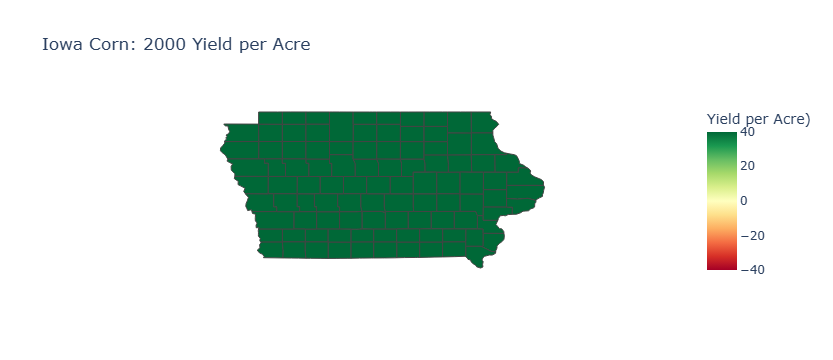

In [5]:
priority_map_df = ia_corn[ia_corn["max_drought_severity"] > 2]
priority_map_df

counties = load_counties()
ia_2000 = priority_map_df[priority_map_df["max_drought_severity"] == 4.0]

fig = px.choropleth(
    ia_2000, geojson=counties, locations="fips", color="yield_per_acre",
    color_continuous_scale="RdYlGn", range_color=(-40, 40),
    hover_name="county_name",
    title="Iowa Corn: 2000 Yield per Acre",
    labels={"yield_per_acre": "Yield per Acre)"},
)
fig.update_geos(fitbounds="locations", visible=False)   # zoom to the counties shown
fig.show()


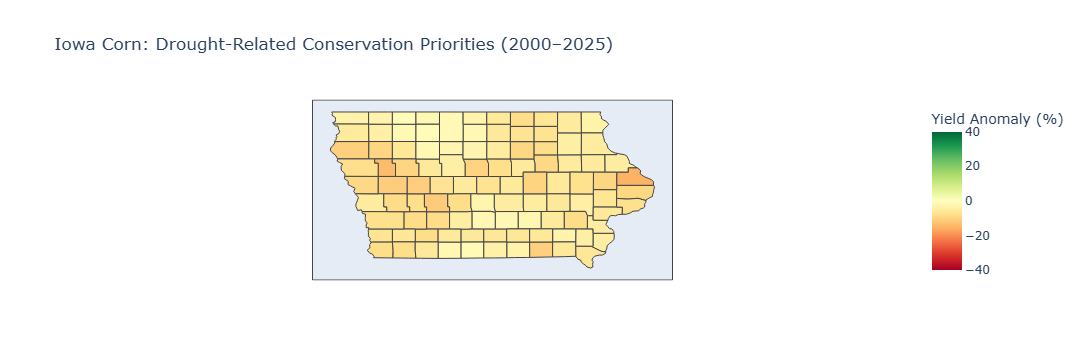

In [10]:
import sys
import plotly.express as px
import pandas as pd
from src.data_loader import load_master
from src.data_loader import load_counties

sys.path.insert(0, "..")

#load dataframe
df = load_master()

# Filter for Iowa corn data
ia_corn = df[
    (df["state_alpha"] == "IA") &
    (df["crop"] == "CORN")
]

# Keep counties experiencing drought severity greater than 2
priority_map_df = ia_corn[
    ia_corn["max_drought_severity"] > 2
]

#If multiple years exist, aggregate data by county
priority_map_df = (
    priority_map_df.groupby(["fips", "county_name"], as_index=False)
    .agg(
        max_drought_severity=("max_drought_severity", "mean"),
        yield_anomaly_pct=("yield_anomaly_pct", "mean")
     )
)

# Load county boundaries
counties = load_counties()

# Create the priority map using average yield anomaly
fig = px.choropleth(
    priority_map_df,
    geojson=counties,
    locations="fips",
    color="yield_anomaly_pct",
    color_continuous_scale="RdYlGn",
    range_color=(-40, 40),
    hover_name="county_name",
    hover_data={
        "max_drought_severity": True,
        "yield_anomaly_pct": ":.2f",
        "fips": False
    },
    title="Iowa Corn: Drought-Related Conservation Priorities (2000–2025)",
    labels={
        "yield_anomaly_pct": "Yield Anomaly (%)",
        "max_drought_severity": "Average Drought Severity"
    }
)

fig.update_geos(fitbounds="locations", visible=False)
fig.show()


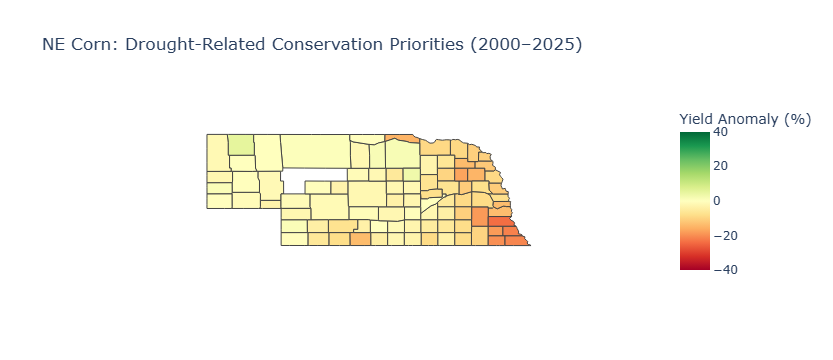

In [17]:
# Filter for Iowa corn data
ne_corn = df[
    (df["state_alpha"] == "NE") &
    (df["crop"] == "CORN")
]

# Keep counties experiencing drought severity greater than 2
priority_ne_map_df = ne_corn[
    ne_corn["max_drought_severity"] > 2
    ]

#If multiple years exist, aggregate data by county
priority_ne_map_df = (
    priority_ne_map_df.groupby(["fips", "county_name"], as_index=False)
    .agg(
        max_drought_severity=("max_drought_severity", "mean"),
        yield_anomaly_pct=("yield_anomaly_pct", "mean")
     )
)


# Create the priority map using average yield anomaly
fig_ne = px.choropleth(
    priority_ne_map_df,
    geojson=counties,
    locations="fips",
    color="yield_anomaly_pct",
    color_continuous_scale="RdYlGn",
    range_color=(-40, 40),
    hover_name="county_name",
    hover_data={
        "max_drought_severity": True,
        "yield_anomaly_pct": ":.2f",
        "fips": False
    },
    title="NE Corn: Drought-Related Conservation Priorities (2000–2025)",
    labels={
        "yield_anomaly_pct": "Yield Anomaly (%)",
        "max_drought_severity": "Average Drought Severity"
    }
)

fig_ne.update_geos(fitbounds="locations", visible=False)
fig_ne.show()


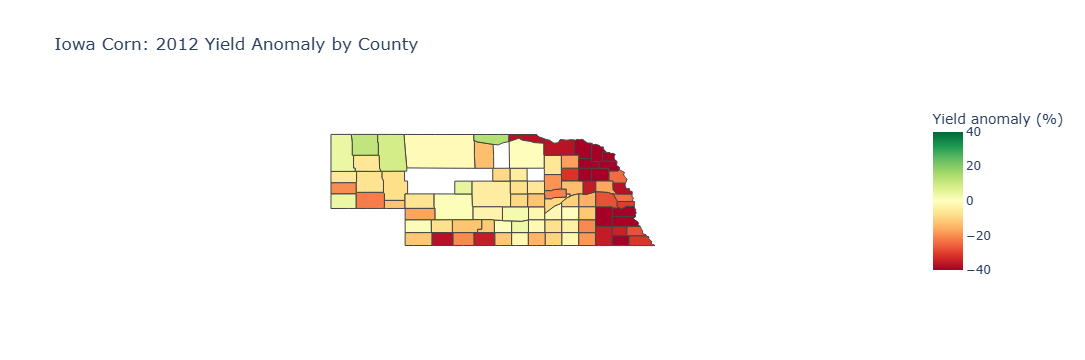

In [16]:
ne_2012 = ne_corn[ne_corn["year"] == 2012]

fig = px.choropleth(
    ne_2012, geojson=counties, locations="fips", color="yield_anomaly_pct",
    color_continuous_scale="RdYlGn", range_color=(-40, 40),
    hover_name="county_name",
    title="Iowa Corn: 2012 Yield Anomaly by County",
    labels={"yield_anomaly_pct": "Yield anomaly (%)"},
)
fig.update_geos(fitbounds="locations", visible=False)   # zoom to the counties shown
fig.show()

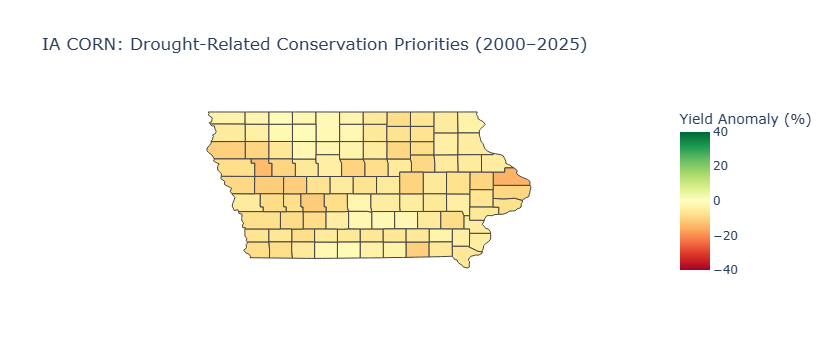

In [6]:
import sys
import plotly.express as px
import pandas as pd
from src.data_loader import load_master
from src.data_loader import load_counties

sys.path.insert(0, "..")

#load dataframe
df = load_master()

#make the dataframe for the state and crop inputed
def state_make_df(state, crop):
    state_df = df[
        (df["state_alpha"] == state) &
        (df["crop"] == crop)
    ]
    return state_df 

# Keep counties experiencing drought severity greater than 2
def state_priority_map(state, crop, state_df):
    state_df = state_make_df(state, crop)
    priority_map_df = state_df[
        state_df["max_drought_severity"] > 2
    ]
    #If multiple years exist, aggregate data by county
    priority_map_df = (
        priority_map_df.groupby(["fips", "county_name"], as_index=False)
        .agg(
            max_drought_severity=("max_drought_severity", "mean"),
            yield_anomaly_pct=("yield_anomaly_pct", "mean")
         )
    )
    return priority_map_df

def plot_state_df(state, crop, priority_map_df):
    # Load county boundaries
    counties = load_counties()
    
    # Create the priority map using average yield anomaly
    fig = px.choropleth(
        priority_map_df,
        geojson=counties,
        locations="fips",
        color="yield_anomaly_pct",
        color_continuous_scale="RdYlGn",
        range_color=(-40, 40),
        hover_name="county_name",
        hover_data={
            "max_drought_severity": True,
            "yield_anomaly_pct": ":.2f",
            "fips": False
        },
        title=f"{state} {crop}: Drought-Related Conservation Priorities (2000–2025)",
        labels={
            "yield_anomaly_pct": "Yield Anomaly (%)",
            "max_drought_severity": "Average Drought Severity"
        }
    )
    fig.update_geos(fitbounds="locations", visible=False)
    fig.show()

de_df = state_make_df('IA', 'CORN')
de_priority_map = state_priority_map('IA', 'CORN', de_df)
plot_state_df('IA', 'CORN', de_priority_map)


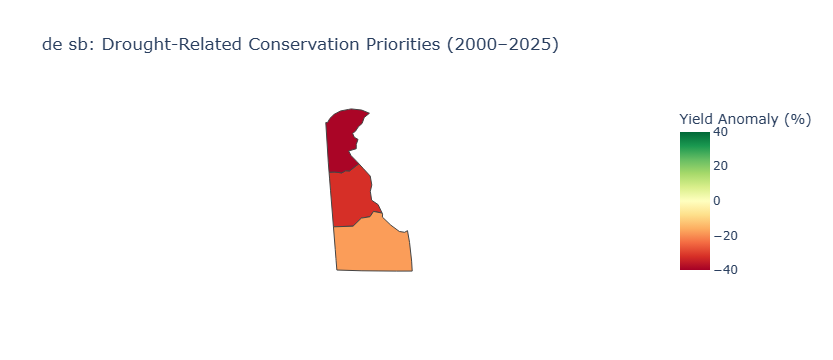

In [16]:
# Filter for Iowa corn data
de_sb = df[
    (df["state_alpha"] == "DE") &
    (df["crop"] == "CORN")
]

# Keep counties experiencing drought severity greater than 2
priority_de_map_df = de_sb[
    de_sb["max_drought_severity"] > 2
    ]

#If multiple years exist, aggregate data by county
priority_de_map_df = (
    priority_de_map_df.groupby(["fips", "county_name"], as_index=False)
    .agg(
        max_drought_severity=("max_drought_severity", "mean"),
        yield_anomaly_pct=("yield_anomaly_pct", "mean")
     )
)

# Load county boundaries
counties = load_counties()

# Create the priority map using average yield anomaly
fig_ne = px.choropleth(
    priority_de_map_df,
    geojson=counties,
    locations="fips",
    color="yield_anomaly_pct",
    color_continuous_scale="RdYlGn",
    range_color=(-40, 40),
    hover_name="county_name",
    hover_data={
        "max_drought_severity": True,
        "yield_anomaly_pct": ":.2f",
        "fips": False
    },
    title="de sb: Drought-Related Conservation Priorities (2000–2025)",
    labels={
        "yield_anomaly_pct": "Yield Anomaly (%)",
        "max_drought_severity": "Average Drought Severity"
    }
)

fig_ne.update_geos(fitbounds="locations", visible=False)
fig_ne.show()


In [11]:
de_test = (df["state_alpha"] == "DE") & (df["crop"] == "SOYBEAN")
de_test.head()

0    False
1    False
2    False
3    False
4    False
dtype: bool

In [7]:
import sys
print(sys.executable)

C:\Users\lacot\DSU-Hackathon-2026-Team-Shark\.venv\Scripts\python.exe


In [3]:
import sys
import plotly.express as px
import pandas as pd
from src.data_loader import load_master
from src.data_loader import load_counties

df = load_master()

In [4]:
print(df.columns.tolist())

['fips', 'county_name', 'state_alpha', 'year', 'crop', 'yield_per_acre', 'yield_status', 'acres_planted', 'acres_harvested', 'yield_anomaly_pct', 'precip_mm', 'precip_anomaly_pct', 'tavg_c', 'extreme_heat_days', 'gdd', 'max_drought_severity', 'weeks_in_d2_plus', 'mean_dsci', 'aws_100cm_mm', 'droughty_pct', 'nccpi_crop']


In [5]:
print(df['state_alpha'].unique())

['CA' 'DE' 'IA' 'NE']


In [6]:
print(df['crop'].unique())

['CORN' 'WHEAT' 'SORGHUM' 'SOYBEANS']


In [7]:
print(df[[
    "state_alpha",
    "crop",
    "year",
    "aws_100cm_mm",
    "droughty_pct",
    "nccpi_crop",
    "max_drought_severity",
    "weeks_in_d2_plus",
    "yield_anomaly_pct"
]].head())

  state_alpha  crop  year  aws_100cm_mm  droughty_pct  nccpi_crop  \
0          CA  CORN  2000    116.899535     62.153917      0.0675   
1          CA  CORN  2001    116.899535     62.153917      0.0675   
2          CA  CORN  2002    116.899535     62.153917      0.0675   
3          CA  CORN  2003    116.899535     62.153917      0.0675   
4          CA  CORN  2004    116.899535     62.153917      0.0675   

   max_drought_severity  weeks_in_d2_plus  yield_anomaly_pct  
0                   0.0               0.0                NaN  
1                   2.0               0.0                NaN  
2                   1.0               0.0                NaN  
3                   0.0               0.0                NaN  
4                   1.0               0.0                NaN  


In [8]:
print("Total rows:", len(df))

print("\nUsable yield anomaly:")
print(df["yield_anomaly_pct"].notna().sum())

print("\nMissing yield anomaly:")
print(df["yield_anomaly_pct"].isna().sum())

print("\nUsable rows by state:")
print(
    df.groupby("state_alpha")["yield_anomaly_pct"]
      .apply(lambda x: x.notna().sum())
)

print("\nUsable rows by state and crop:")
print(
    df.groupby(["state_alpha", "crop"])["yield_anomaly_pct"]
      .apply(lambda x: x.notna().sum())
)

Total rows: 17056

Usable yield anomaly:
10995

Missing yield anomaly:
6061

Usable rows by state:
state_alpha
CA     514
DE     180
IA    4907
NE    5394
Name: yield_anomaly_pct, dtype: int64

Usable rows by state and crop:
state_alpha  crop    
CA           CORN         201
             SORGHUM        0
             WHEAT        313
DE           CORN          78
             SORGHUM        0
             SOYBEANS      72
             WHEAT         30
IA           CORN        2470
             SOYBEANS    2437
             WHEAT          0
NE           CORN        2058
             SORGHUM      433
             SOYBEANS    1709
             WHEAT       1194
Name: yield_anomaly_pct, dtype: int64


In [9]:
# Keep rows with usable yield anomaly and D2+ drought
analysis_df = df[
    df["yield_anomaly_pct"].notna() &
    (df["max_drought_severity"] > 3)
].copy()

print("Usable drought-year observations:", len(analysis_df))

print("\nDrought-year observations by state:")
print(analysis_df.groupby("state_alpha").size())

print("\nDrought-year observations by state and crop:")
print(analysis_df.groupby(["state_alpha", "crop"]).size())

print("\nSoil storage summary by state:")
print(analysis_df.groupby("state_alpha")["aws_100cm_mm"].describe()[["count", "min", "50%", "max"]])

Usable drought-year observations: 1999

Drought-year observations by state:
state_alpha
CA      96
DE      11
IA     594
NE    1298
dtype: int64

Drought-year observations by state and crop:
state_alpha  crop    
CA           CORN         29
             WHEAT        67
DE           CORN          3
             SOYBEANS      3
             WHEAT         5
IA           CORN        277
             SOYBEANS    317
NE           CORN        471
             SORGHUM     114
             SOYBEANS    397
             WHEAT       316
dtype: int64

Soil storage summary by state:
              count         min         50%         max
state_alpha                                            
CA             96.0   79.438243  116.461267  138.605607
DE             11.0  109.985282  152.392026  156.597960
IA            594.0  154.245463  178.999037  205.757359
NE           1298.0   70.006739  176.159081  214.283084


In [10]:
print("Unique counties in drought-year data:")
print(analysis_df.groupby(["state_alpha", "crop"])["fips"].nunique())

print("\nUnique counties by state:")
print(analysis_df.groupby("state_alpha")["fips"].nunique())

Unique counties in drought-year data:
state_alpha  crop    
CA           CORN        13
             WHEAT       19
DE           CORN         3
             SOYBEANS     3
             WHEAT        3
IA           CORN        99
             SOYBEANS    99
NE           CORN        89
             SORGHUM     30
             SOYBEANS    76
             WHEAT       59
Name: fips, dtype: int64

Unique counties by state:
state_alpha
CA    19
DE     3
IA    99
NE    89
Name: fips, dtype: int64


In [16]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# STEP 1: Start with usable drought-year observations
# ---------------------------------------------------------
analysis_df = df[
    df["yield_anomaly_pct"].notna() &
    (df["max_drought_severity"] >= 3) &
    df["aws_100cm_mm"].notna()
].copy()

analysis_df

,fips,county_name,state_alpha,year,crop,yield_per_acre,yield_status,acres_planted,acres_harvested,yield_anomaly_pct,...,precip_anomaly_pct,tavg_c,extreme_heat_days,gdd,max_drought_severity,weeks_in_d2_plus,mean_dsci,aws_100cm_mm,droughty_pct,nccpi_crop
106,06007,Butte County,CA,2002,WHEAT,68.0,reported,2000.0,1000.0,4.13,...,2.01,13.44,4.0,3916.0,4.0,16.0,127.5,109.178248,74.786329,0.3439
118,06007,Butte County,CA,2014,WHEAT,62.5,reported,3500.0,800.0,-5.05,...,-34.87,14.31,5.0,4193.0,4.0,43.0,350.3,109.178248,74.786329,0.3439
131,06011,Colusa County,CA,2001,CORN,134.4,reported,3500.0,3200.0,-17.08,...,-58.20,22.84,34.0,1752.0,3.0,3.0,95.5,126.878255,74.330904,0.1023
143,06011,Colusa County,CA,2013,CORN,197.5,reported,8000.0,8000.0,1.65,...,102.54,22.53,31.0,1716.0,3.0,14.0,266.7,126.878255,74.330904,0.1023
151,06011,Colusa County,CA,2021,CORN,195.1,reported,2000.0,1440.0,-9.58,...,-92.43,23.81,65.0,1808.0,5.0,22.0,484.6,126.878255,74.330904,0.1023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17016,31185,York County,NE,2012,SOYBEANS,55.9,reported,96600.0,96200.0,-6.80,...,-55.18,19.66,27.0,1843.0,4.0,15.0,241.4,191.744163,0.000000,0.6556
17017,31185,York County,NE,2013,SOYBEANS,57.9,reported,88100.0,87900.0,-4.71,...,-1.09,19.28,12.0,1789.0,3.0,3.0,191.5,191.744163,0.000000,0.6556
17026,31185,York County,NE,2022,SOYBEANS,64.6,reported,122500.0,121600.0,-4.76,...,-17.93,19.71,6.0,1866.0,3.0,7.0,112.1,191.744163,0.000000,0.6556
17027,31185,York County,NE,2023,SOYBEANS,59.4,reported,94900.0,93400.0,-13.43,...,-30.89,19.92,11.0,1886.0,5.0,27.0,444.8,191.744163,0.000000,0.6556


In [19]:
county_soil = (
    df[
        df["aws_100cm_mm"].notna()
    ][
        [
            "state_alpha",
            "crop",
            "fips",
            "county_name",
            "aws_100cm_mm"
        ]
    ]
    .drop_duplicates(
        subset=["state_alpha", "crop", "fips"]
    )
)
county_soil

,state_alpha,crop,fips,county_name,aws_100cm_mm
0,CA,CORN,06001,Alameda County,116.899535
26,CA,WHEAT,06001,Alameda County,116.899535
52,CA,CORN,06005,Amador County,80.595665
78,CA,CORN,06007,Butte County,109.178248
104,CA,WHEAT,06007,Butte County,109.178248
...,...,...,...,...,...
16926,NE,WHEAT,31183,Wheeler County,83.149014
16952,NE,CORN,31185,York County,191.744163
16978,NE,SORGHUM,31185,York County,191.744163
17004,NE,SOYBEANS,31185,York County,191.744163


In [20]:
# ---------------------------------------------------------
# STEP 3: Find the median soil storage within each
# state + crop combination
# ---------------------------------------------------------
county_soil["soil_median"] = (
    county_soil
    .groupby(["state_alpha", "crop"])["aws_100cm_mm"]
    .transform("median")
)

county_soil

,state_alpha,crop,fips,county_name,aws_100cm_mm,soil_median
0,CA,CORN,06001,Alameda County,116.899535,107.418022
26,CA,WHEAT,06001,Alameda County,116.899535,103.522584
52,CA,CORN,06005,Amador County,80.595665,107.418022
78,CA,CORN,06007,Butte County,109.178248,107.418022
104,CA,WHEAT,06007,Butte County,109.178248,103.522584
...,...,...,...,...,...,...
16926,NE,WHEAT,31183,Wheeler County,83.149014,174.749769
16952,NE,CORN,31185,York County,191.744163,174.749769
16978,NE,SORGHUM,31185,York County,191.744163,172.772832
17004,NE,SOYBEANS,31185,York County,191.744163,177.758154


In [21]:
# ---------------------------------------------------------
# STEP 4: Divide counties into High vs Low soil storage
# ---------------------------------------------------------
county_soil["soil_group"] = np.where(
    county_soil["aws_100cm_mm"] >= county_soil["soil_median"],
    "High",
    "Low"
)
county_soil

,state_alpha,crop,fips,county_name,aws_100cm_mm,soil_median,soil_group
0,CA,CORN,06001,Alameda County,116.899535,107.418022,High
26,CA,WHEAT,06001,Alameda County,116.899535,103.522584,High
52,CA,CORN,06005,Amador County,80.595665,107.418022,Low
78,CA,CORN,06007,Butte County,109.178248,107.418022,High
104,CA,WHEAT,06007,Butte County,109.178248,103.522584,High
...,...,...,...,...,...,...,...
16926,NE,WHEAT,31183,Wheeler County,83.149014,174.749769,Low
16952,NE,CORN,31185,York County,191.744163,174.749769,High
16978,NE,SORGHUM,31185,York County,191.744163,172.772832,High
17004,NE,SOYBEANS,31185,York County,191.744163,177.758154,High


In [26]:
# ---------------------------------------------------------
# STEP 5: Attach ONLY the soil group to drought data
# ---------------------------------------------------------
analysis_df = analysis_df.merge(
    county_soil[
        [
            "state_alpha",
            "crop",
            "fips",
            "soil_group"
        ]
    ],
    on=["state_alpha", "crop", "fips"],
    how="inner"
)

analysis_df

MergeError: Passing 'suffixes' which cause duplicate columns {'soil_group_y', 'soil_group_x'} is not allowed.

In [12]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# STEP 1: Start with usable drought-year observations
# ---------------------------------------------------------
analysis_df = df[
    df["yield_anomaly_pct"].notna() &
    (df["max_drought_severity"] >= 3) &
    df["aws_100cm_mm"].notna()
].copy()


# ---------------------------------------------------------
# STEP 2: Get ONE soil-storage value per county/crop
# ---------------------------------------------------------
county_soil = (
    df[
        df["aws_100cm_mm"].notna()
    ][
        [
            "state_alpha",
            "crop",
            "fips",
            "county_name",
            "aws_100cm_mm"
        ]
    ]
    .drop_duplicates(
        subset=["state_alpha", "crop", "fips"]
    )
)


# ---------------------------------------------------------
# STEP 3: Find the median soil storage within each
# state + crop combination
# ---------------------------------------------------------
county_soil["soil_median"] = (
    county_soil
    .groupby(["state_alpha", "crop"])["aws_100cm_mm"]
    .transform("median")
)


# ---------------------------------------------------------
# STEP 4: Divide counties into High vs Low soil storage
# ---------------------------------------------------------
county_soil["soil_group"] = np.where(
    county_soil["aws_100cm_mm"] >= county_soil["soil_median"],
    "High",
    "Low"
)


# ---------------------------------------------------------
# STEP 5: Attach ONLY the soil group to drought data
# ---------------------------------------------------------
analysis_df = analysis_df.merge(
    county_soil[
        [
            "state_alpha",
            "crop",
            "fips",
            "soil_group"
        ]
    ],
    on=["state_alpha", "crop", "fips"],
    how="inner"
)


# ---------------------------------------------------------
# STEP 6: Average each county's yield anomaly across
# its D2+ drought years
# ---------------------------------------------------------
county_drought = (
    analysis_df
    .groupby(
        [
            "state_alpha",
            "crop",
            "fips",
            "soil_group"
        ],
        as_index=False
    )
    .agg(
        aws_100cm_mm=("aws_100cm_mm", "first"),
        drought_yield_anomaly=("yield_anomaly_pct", "mean"),
        drought_years=("year", "nunique")
    )
)


# ---------------------------------------------------------
# STEP 7: Count counties in each state/crop
# ---------------------------------------------------------
county_counts = (
    county_drought
    .groupby(["state_alpha", "crop"])["fips"]
    .nunique()
    .reset_index(name="county_count")
)

valid_combinations = county_counts[
    county_counts["county_count"] >= 10
][
    ["state_alpha", "crop"]
]


county_drought = county_drought.merge(
    valid_combinations,
    on=["state_alpha", "crop"],
    how="inner"
)


# ---------------------------------------------------------
# STEP 8: Calculate average drought loss for High vs Low
# ---------------------------------------------------------
results = (
    county_drought
    .groupby(
        ["state_alpha", "crop", "soil_group"]
    )
    .agg(
        counties=("fips", "nunique"),
        avg_drought_yield_anomaly=(
            "drought_yield_anomaly",
            "mean"
        )
    )
    .reset_index()
)


# ---------------------------------------------------------
# STEP 9: Put High and Low side-by-side
# ---------------------------------------------------------
comparison = results.pivot_table(
    index=["state_alpha", "crop"],
    columns="soil_group",
    values=[
        "counties",
        "avg_drought_yield_anomaly"
    ]
)

comparison.columns = [
    f"{col[1].lower()}_{col[0]}"
    for col in comparison.columns
]

comparison = comparison.reset_index()


# ---------------------------------------------------------
# STEP 10: Calculate High - Low
# ---------------------------------------------------------
comparison["high_minus_low"] = (
    comparison["high_avg_drought_yield_anomaly"]
    -
    comparison["low_avg_drought_yield_anomaly"]
)


print("HIGH vs LOW SOIL STORAGE DURING D2+ DROUGHT")
print("=" * 70)
print(comparison.round(2).to_string(index=False))

HIGH vs LOW SOIL STORAGE DURING D2+ DROUGHT
state_alpha     crop  high_avg_drought_yield_anomaly  low_avg_drought_yield_anomaly  high_counties  low_counties  high_minus_low
         CA     CORN                           -1.52                           2.34            7.0           6.0           -3.86
         CA    WHEAT                            2.27                           0.73           11.0           8.0            1.54
         IA     CORN                           -6.39                          -5.68           50.0          49.0           -0.71
         IA SOYBEANS                           -5.40                          -6.11           50.0          49.0            0.71
         NE     CORN                           -7.90                          -3.78           46.0          43.0           -4.12
         NE  SORGHUM                          -12.47                         -14.15           22.0           8.0            1.68
         NE SOYBEANS                           -7.21 

In [13]:
import numpy as np

def bootstrap_difference(data, n_boot=2000, random_state=42):
    rng = np.random.default_rng(random_state)

    high = data[data["soil_group"] == "High"]["drought_yield_anomaly"].dropna().values
    low = data[data["soil_group"] == "Low"]["drought_yield_anomaly"].dropna().values

    if len(high) < 2 or len(low) < 2:
        return np.nan, np.nan, np.nan

    differences = []

    for _ in range(n_boot):
        high_sample = rng.choice(
            high,
            size=len(high),
            replace=True
        )

        low_sample = rng.choice(
            low,
            size=len(low),
            replace=True
        )

        differences.append(
            high_sample.mean() - low_sample.mean()
        )

    differences = np.array(differences)

    return (
        differences.mean(),
        np.percentile(differences, 2.5),
        np.percentile(differences, 97.5)
    )


bootstrap_results = []

for (state, crop), group in county_drought.groupby(
    ["state_alpha", "crop"]
):
    estimate, lower, upper = bootstrap_difference(group)

    bootstrap_results.append({
        "state_alpha": state,
        "crop": crop,
        "estimate": estimate,
        "lower_95": lower,
        "upper_95": upper
    })


bootstrap_results = pd.DataFrame(bootstrap_results)

print("BOOTSTRAP ESTIMATES")
print("=" * 70)
print(bootstrap_results.round(2).to_string(index=False))

BOOTSTRAP ESTIMATES
state_alpha     crop  estimate  lower_95  upper_95
         CA     CORN     -3.87     -7.40     -0.41
         CA    WHEAT      1.53     -1.12      4.36
         IA     CORN     -0.72     -1.79      0.42
         IA SOYBEANS      0.71     -0.68      2.09
         NE     CORN     -4.13     -6.55     -1.64
         NE  SORGHUM      1.69     -2.90      6.16
         NE SOYBEANS     -1.11     -3.39      1.30
         NE    WHEAT      0.19     -4.04      4.45
